In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df=pd.read_csv("Titanic-Dataset.csv")

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.shape

(891, 12)

In [5]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [6]:
df=df.drop("Cabin",axis=1)

In [7]:
df=df.drop("Name",axis=1)

In [8]:
df["Age"]=df["Age"].fillna(df["Age"].mean())

In [9]:
df["Age"].isnull().sum()

np.int64(0)

In [10]:
df.head()
df["Embarked"].isnull().sum()

np.int64(2)

In [11]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [12]:
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,female,35.0,1,0,113803,53.1000,S
4,5,0,3,male,35.0,0,0,373450,8.0500,S


In [13]:
df = pd.get_dummies(
    df,
    columns=["Sex", "Embarked"],
    drop_first=True,
    dtype=int
)

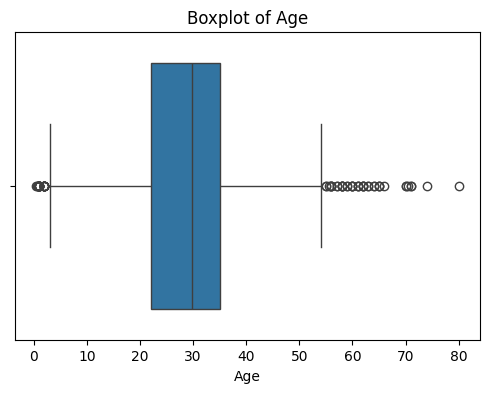

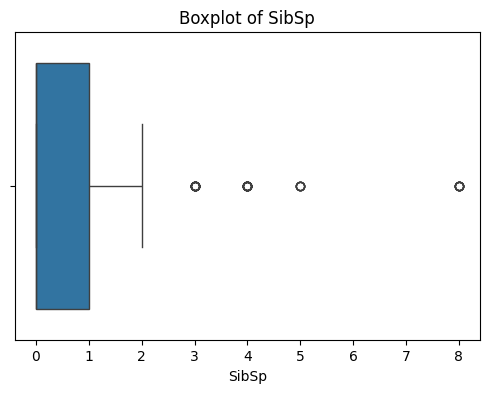

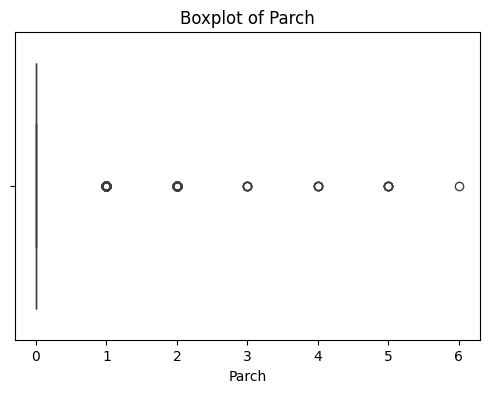

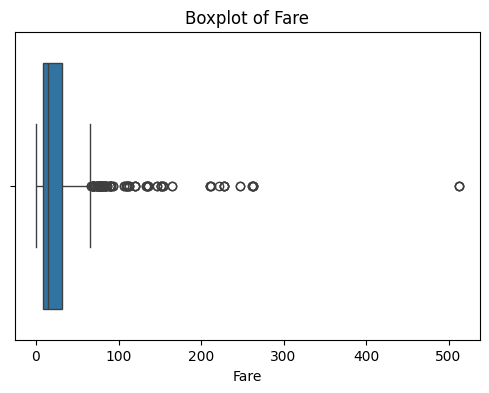

In [14]:
numeric_cols = ["Age", "SibSp", "Parch", "Fare"]

for col in numeric_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

### Outliers remove 

In [15]:
outlier_cols = ["Age", "SibSp", "Parch", "Fare"]

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[
        (df[col] >= lower) &
        (df[col] <= upper)
    ]

In [16]:
print(df.shape)

(561, 11)


### Numerical features standardize 

In [18]:
from sklearn.preprocessing import StandardScaler
scale_cols = ["Age", "SibSp", "Parch", "Fare"]

scaler = StandardScaler()

df[scale_cols] = scaler.fit_transform(df[scale_cols])

In [19]:
print(df.head())

   PassengerId  Survived  Pclass       Age     SibSp  Parch            Ticket  \
0            1         0       3 -0.903434  1.839399    0.0         A/5 21171   
2            3         1       3 -0.428774 -0.433515    0.0  STON/O2. 3101282   
3            4         1       1  0.639211  1.839399    0.0            113803   
4            5         0       3  0.639211 -0.433515    0.0            373450   
5            6         0       3  0.010181 -0.433515    0.0            330877   

       Fare  Sex_male  Embarked_Q  Embarked_S  
0 -0.613957         1           0           1  
2 -0.549982         0           0           1  
3  3.731563         0           0           1  
4 -0.538135         1           0           1  
5 -0.499438         1           1           0  


In [21]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
Index: 561 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  561 non-null    int64  
 1   Survived     561 non-null    int64  
 2   Pclass       561 non-null    int64  
 3   Age          561 non-null    float64
 4   SibSp        561 non-null    float64
 5   Parch        561 non-null    float64
 6   Ticket       561 non-null    object 
 7   Fare         561 non-null    float64
 8   Sex_male     561 non-null    int64  
 9   Embarked_Q   561 non-null    int64  
 10  Embarked_S   561 non-null    int64  
dtypes: float64(4), int64(6), object(1)
memory usage: 52.6+ KB
None


In [22]:
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Sex_male       0
Embarked_Q     0
Embarked_S     0
dtype: int64


In [23]:
print(df.head())

   PassengerId  Survived  Pclass       Age     SibSp  Parch            Ticket  \
0            1         0       3 -0.903434  1.839399    0.0         A/5 21171   
2            3         1       3 -0.428774 -0.433515    0.0  STON/O2. 3101282   
3            4         1       1  0.639211  1.839399    0.0            113803   
4            5         0       3  0.639211 -0.433515    0.0            373450   
5            6         0       3  0.010181 -0.433515    0.0            330877   

       Fare  Sex_male  Embarked_Q  Embarked_S  
0 -0.613957         1           0           1  
2 -0.549982         0           0           1  
3  3.731563         0           0           1  
4 -0.538135         1           0           1  
5 -0.499438         1           1           0  


### Survival Count — kitne survived / not survived 

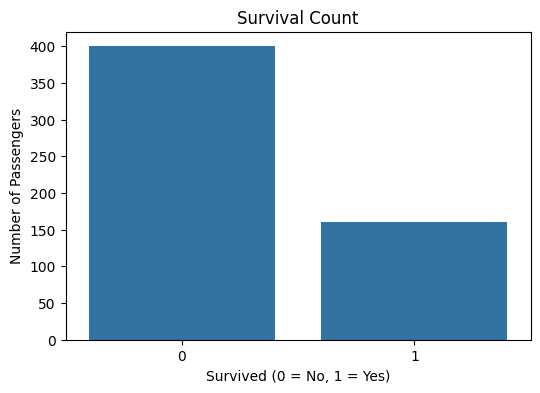

In [24]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Survived")
plt.title("Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

### Age Distribution

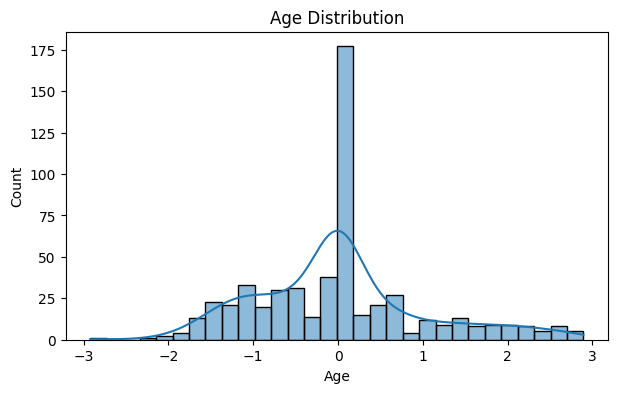

In [25]:
plt.figure(figsize=(7,4))
sns.histplot(df["Age"], bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

### Fare Distribution

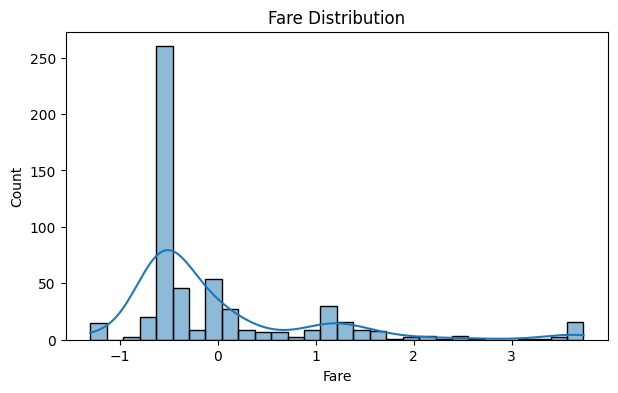

In [26]:
plt.figure(figsize=(7,4))
sns.histplot(df["Fare"], bins=30, kde=True)
plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Count")
plt.show()

### Boxplot

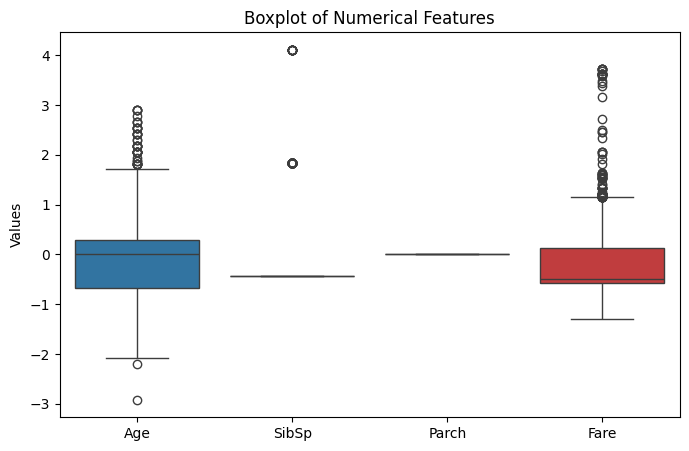

In [27]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df[["Age", "SibSp", "Parch", "Fare"]])
plt.title("Boxplot of Numerical Features")
plt.ylabel("Values")
plt.show()